### This .ipynb file is strictly for my practice for week 7 before attempting or while attemping the week7 task and assignments

In [12]:
import warnings
warnings.simplefilter('ignore', FutureWarning)

import pandas as pd

# Load Data from cohort database (schema week08). See "Data Access (SQL).md".
import sys, pathlib
_p = pathlib.Path.cwd()
while _p != _p.parent and not (_p / "db" / "dataraflow_db.py").exists():
    _p = _p.parent
sys.path.insert(0, str(_p))
from db.dataraflow_db import run_query

In [13]:
#Importing the data and storing it in a pandas dataframe
london = run_query("""
    SELECT *
    FROM week07.london_2014
""")

In [14]:
#Practicing Renaming the column with the HTML character
london.columns = london.columns.str.strip()
london = london.rename(columns ={'WindDirDegrees<br />': 'WindDirDegrees'})
london.head(2)

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186<br />
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214<br />


In [15]:
#Replacing the break character attached to last column in the dataframe
london['WindDirDegrees'] = london['WindDirDegrees'].astype(str).str.replace('<br />', '', regex = False).astype(int)
london.head(2)

,GMT,Max TemperatureC,Mean TemperatureC,Min TemperatureC,Dew PointC,MeanDew PointC,Min DewpointC,Max Humidity,Mean Humidity,Min Humidity,...,Max VisibilityKm,Mean VisibilityKm,Min VisibilitykM,Max Wind SpeedKm/h,Mean Wind SpeedKm/h,Max Gust SpeedKm/h,Precipitationmm,CloudCover,Events,WindDirDegrees
0,2014-1-1,11,8,6,9,7,4,94,86,73,...,31,11,2,40,26,66.0,9.91,4.0,Rain,186
1,2014-1-2,11,9,6,9,6,4,94,81,60,...,31,15,5,32,21,50.0,1.02,2.0,Rain,214


In [16]:
#practing loading a dataframe to CSV file
london.to_csv('clean_london_2014.csv', index = False)

In [17]:
#Loading the data back from the csv file and checking the condition of the column names
new_data = pd.read_csv('clean_london_2014.csv')
new_data.columns

Index(['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC',
       'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity',
       'Mean Humidity', 'Min Humidity', 'Max Sea Level PressurehPa',
       'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa',
       'Max VisibilityKm', 'Mean VisibilityKm', 'Min VisibilitykM',
       'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Max Gust SpeedKm/h',
       'Precipitationmm', 'CloudCover', 'Events', 'WindDirDegrees'],
      dtype='str')

In [18]:
#Changing a column to datatime datatype
new_data['GMT'] = pd.to_datetime(new_data['GMT'])
new_data['GMT'].dtype
new_data['GMT']

0     2014-01-01
1     2014-01-02
2     2014-01-03
3     2014-01-04
4     2014-01-05
         ...    
360   2014-12-27
361   2014-12-28
362   2014-12-29
363   2014-12-30
364   2014-12-31
Name: GMT, Length: 365, dtype: datetime64[us]

<Axes: >

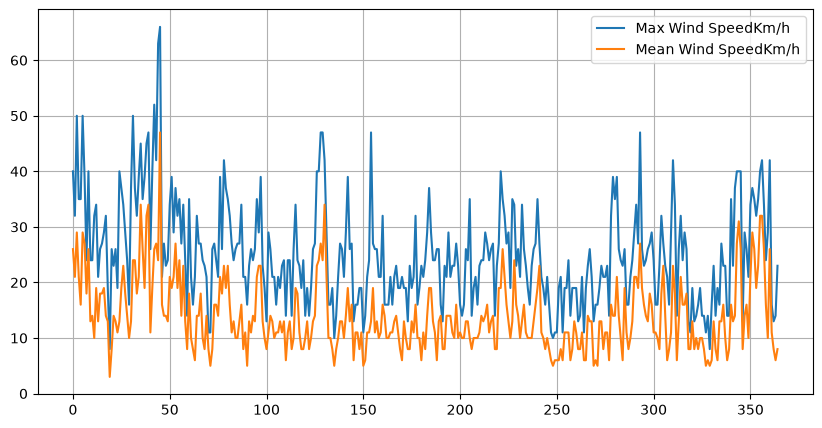

In [19]:
london[['Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h']].plot(grid=True, figsize=(10,5))

In [20]:
london_data = run_query("""
    SELECT *
    FROM week07.london_2014
""")

In [21]:
london_data.columns = london_data.columns.str.strip()
london_data.columns

Index(['GMT', 'Max TemperatureC', 'Mean TemperatureC', 'Min TemperatureC',
       'Dew PointC', 'MeanDew PointC', 'Min DewpointC', 'Max Humidity',
       'Mean Humidity', 'Min Humidity', 'Max Sea Level PressurehPa',
       'Mean Sea Level PressurehPa', 'Min Sea Level PressurehPa',
       'Max VisibilityKm', 'Mean VisibilityKm', 'Min VisibilitykM',
       'Max Wind SpeedKm/h', 'Mean Wind SpeedKm/h', 'Max Gust SpeedKm/h',
       'Precipitationmm', 'CloudCover', 'Events', 'WindDirDegrees<br />'],
      dtype='str')

In [22]:
london_data = london_data.rename(columns = {'WindDirDegrees<br />': 'WindDirDegrees'})
london_data['GMT'] = pd.to_datetime(london_data['GMT'])
for x in london_data.columns:
    print(x, '====', london_data[f'{x}'].dtype)

GMT ==== datetime64[us]
Max TemperatureC ==== int64
Mean TemperatureC ==== int64
Min TemperatureC ==== int64
Dew PointC ==== int64
MeanDew PointC ==== int64
Min DewpointC ==== int64
Max Humidity ==== int64
Mean Humidity ==== int64
Min Humidity ==== int64
Max Sea Level PressurehPa ==== int64
Mean Sea Level PressurehPa ==== int64
Min Sea Level PressurehPa ==== int64
Max VisibilityKm ==== int64
Mean VisibilityKm ==== int64
Min VisibilitykM ==== int64
Max Wind SpeedKm/h ==== int64
Mean Wind SpeedKm/h ==== int64
Max Gust SpeedKm/h ==== float64
Precipitationmm ==== float64
CloudCover ==== float64
Events ==== str
WindDirDegrees ==== str


In [23]:
london_data['WindDirDegrees'] = london_data['WindDirDegrees'].astype(str).str.replace('<br />', '', regex = False).astype(int)
london_data['WindDirDegrees'].dtype

dtype('int64')

In [24]:
#SQL Task 01
run_query("""
    WITH windDir AS (SELECT  [WindDirDegrees<br />],
                        CAST(REPLACE([WindDirDegrees<br />], '<br />', '') AS INT) AS WindDirDegrees
                    FROM week07.london_2014)
    SELECT COUNT(WindDirDegrees) AS days_over_350
    FROM windDir
    WHERE WindDirDegrees > 350
""")

,days_over_350
0,5


In [25]:
#Solution to SQL Task 2
run_query("""
    SELECT TRY_CONVERT(Date, GMT) AS day,
        [Max TemperatureC],
        [Min TemperatureC]
    FROM week07.london_2014
    WHERE TRY_CONVERT(Date, GMT) BETWEEN '2014-12-08' AND '2014-12-12' 
    ORDER BY day
""")

,day,Max TemperatureC,Min TemperatureC
0,2014-12-08,7,1
1,2014-12-09,12,-1
2,2014-12-10,9,6
3,2014-12-11,10,5
4,2014-12-12,9,2


In [26]:
#Solution to SQL Task 3
#has error regarding the conversion to billion but fized in the original code
run_query("""
    SELECT TOP 10
        a.country,
        ROUND([NY.GDP.MKTP.CD], 2) AS gdp_bn_usd,
        ROUND([SP.DYN.LE00.IN], 1) AS life_expectancy
    FROM week08.wb_gdp_2013 a
    JOIN week08.wb_le_2013 b
        ON a.country = b.country
    WHERE [NY.GDP.MKTP.CD] < 10000000000 AND
        [SP.DYN.LE00.IN] IS NOT NULL
    ORDER BY life_expectancy DESC, country ASC
""")

,country,gdp_bn_usd,life_expectancy
0,Faeroe Islands,2.613459e+09,81.3
1,Malta,9.642849e+09,80.7
2,Bermuda,5.573710e+09,80.6
3,Maldives,2.790660e+09,76.6
4,Antigua and Barbuda,1.200588e+09,75.8
5,Barbados,4.281000e+09,75.3
6,"Bahamas, The",8.431750e+09,75.1
7,St. Lucia,1.334386e+09,74.9
8,Montenegro,4.464260e+09,74.8
9,Seychelles,1.411036e+09,74.2


In [27]:
#SQL Task 4
run_query("""
    SELECT COUNT(*)
    FROM week08.wb_gdp_2013 a
    LEFT JOIN week08.wb_le_2013 b
        ON a.country = b.country
    WHERE [NY.GDP.MKTP.CD] IS NULL OR
    [SP.DYN.LE00.IN] IS NULL

""")

,
0,29


In [28]:
#Confirming the information above
run_query("""
    SELECT *
    FROM week08.wb_gdp_2013
    WHERE [NY.GDP.MKTP.CD] IS NULL
""")
#This shows that they are 23 countries in the GPD Dataset that has no recoreded GDP volumn
#Proofing that 23 of the 29 of the values in the previous code cell

,country,year,NY.GDP.MKTP.CD
0,Not classified,2013,None
1,American Samoa,2013,None
2,Aruba,2013,None
3,Cayman Islands,2013,None
4,Channel Islands,2013,None
5,Curacao,2013,None
6,Eritrea,2013,None
7,French Polynesia,2013,None
8,Greenland,2013,None
9,Guam,2013,None
